<a href="https://colab.research.google.com/github/erskordi/ME538/blob/main/ME538_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Always run this cell to install cantera before proceeding with the rest
!python -m pip install -q cantera

## Gas Generator Cycle

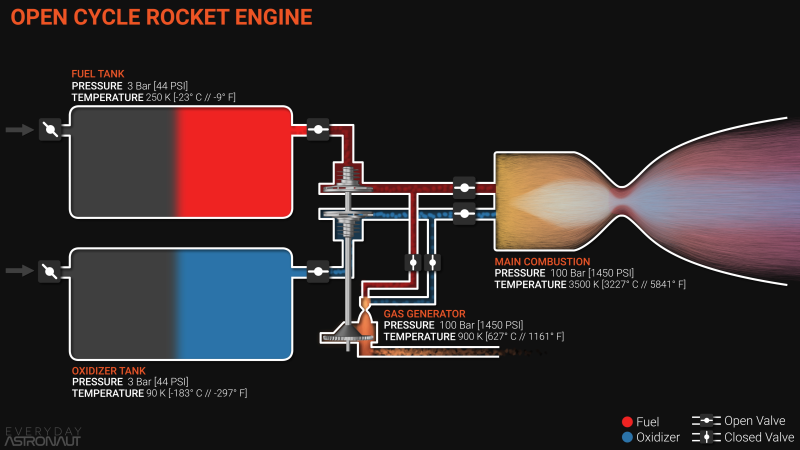

In [5]:
import cantera as ct
import numpy as np

import matplotlib.pyplot as plt

class Config:
  def __init__(self):
    # Propellants
    self.methalox = ("CH4", "O2")
    self.hydrolox = ("H2", "O2")

    # Engine operating parameters
    self.F = 1200 # [kN]
    self.Tc_max = 4000 # [K]
    self.t_operate = 300 # [s]
    self.Pc = np.arange(5, 20, 0.5) # [Mpa]; range
    self.Pa = 0.101325 # [MPa]; sea level

    # Nozzle parameters
    self.area_expansion_ratio = 10 # Ch.3
    self.eta_nozzle = 0.9 # Ch.3

    # Turbopump parameters
    self.eta_fuel_pump = 0.75
    self.eta_lox_pump = 0.75
    self.eta_turbine = 0.5
    self.p_fuel_in = 0.3 # [MPa]
    self.p_lox_in = 0.3 # [MPa]
    self.p_pump_out = 1.5 * self.Pc # [MPa]
    self.eta_m = 1

    # Gas Generator parameters
    self.p_gg = 0.85 * self.Pc # [MPa]
    self.T_gg = 780 # [K]
    self.pi_turbine = 16.5

    # Propellant properties
    self.T_f = {"hydrolox": 20.3, "methalox": 111.7} # [K]
    self.T_lox = {"hydrolox": 90.2, "methalox": 90.2} # [K]
    self.rho_fuel = {"hydrolox": 71, "methalox": 423} # [kg/m^3]
    self.rho_lox = {"hydrolox": 1142, "methalox": 1142} # [kg/m^3]

    # Other constants
    g0 = 9.80665 # [m/s^2]

In [36]:
class GasGenerator:
  def __init__(self):
    self.gas = ct.Solution('gri30.yaml')

  def __str__(self):
    return f"Propellant: {self.propellant}"

  def pump(self):
    """Adiabatically pump a fluid to pressure p_final, using
    a pump with isentropic efficiency eta."""
    h0 = self.gas.h
    s0 = self.gas.s
    self.gas.SP = s0, self.p_final
    h1s = self.gas.h
    isentropic_work = h1s - h0
    actual_work = isentropic_work / self.eta
    h1 = h0 + actual_work
    self.fluid.HP = h1, self.p_final
    return actual_work


  def expand(self):
    """Adiabatically expand a fluid to pressure p_final, using
    a turbine with isentropic efficiency eta."""
    h0 = self.gas.h
    s0 = self.fluid.s
    self.gas.SP =s0, self.p_final
    h1s = self.gas.h
    isentropic_work = h0 - h1s
    actual_work = isentropic_work * self.eta
    h1 = h0 - actual_work
    self.fluid.HP = h1, self.p_final
    return actual_work

  def equivalence_ratio(self, propellant, p):
    fuel = ct.Quantity(self.gas, constant='HP')
    composition = ('CH4:1', 'O2:2') if propellant == config.methalox else ('H2:2', 'O2:1')
    fuel.TPX = 300, p * 1e6, composition[0]

    oxidizer = ct.Quantity(self.gas, constant='HP')
    oxidizer.TPX = 300, p * 1e6, composition[1]

    r_ratios = np.linspace(1.5, 10.0, 50)
    temperatures = []

    for r in r_ratios:
      fuel.mass = 1.0  # 1 kg of fuel
      oxidizer.mass = r  # 'of' kg of oxidizer

      # Mixture
      mixture = fuel + oxidizer
      mixture.equilibrate('HP')
      temperatures.append(mixture.T)

    best_r = r_ratios[np.argmax(temperatures)]
    print(f'Maximum Tempearature: {max(temperatures):.1f} K at r = {best_r:.2f}')
    return np.round(best_r, 2).item()


  def printState(self, n):
      print('\n***************** State {0} ******************'.format(n))
      print(self.gas.report())

In [37]:
# Create objects here
config = Config()

## Optimal O/F ratio

In [39]:
methalox_analysis = GasGenerator()
methalox_analysis.equivalence_ratio(config.methalox, config.Pa)

Maximum Tempearature: 3056.0 K at r = 3.64


3.64

In [ ]:
# Examples for Rankine cycle; We will need something similar
for data in [methalox_data, hydrolox_data]:
  eta_pump = data.eta_pump
  eta_turbine = data.eta_turbine
  p_max = data.p_max
  propellant = data.propellant
  gg = GasGenerator(p_max, (eta_pump, eta_turbine), propellant)